/Users/fangsiyu/dev-env/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


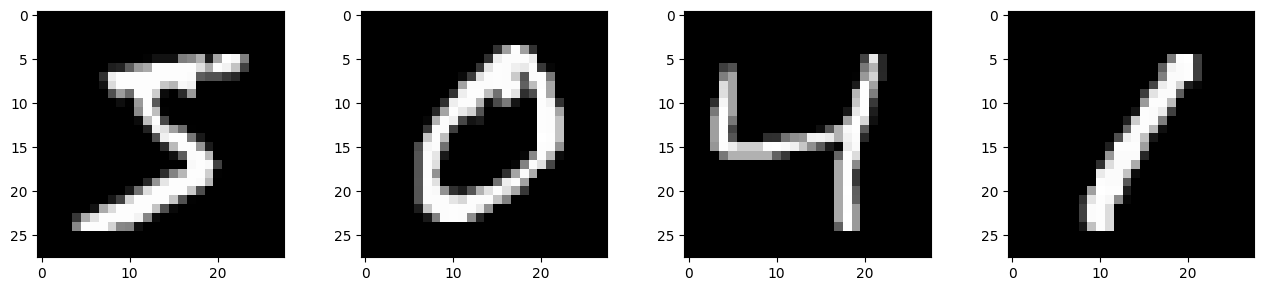

In [ ]:
#@title Classification Example (MNIST Digits)
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from time import time
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Check the images
fig = plt.figure(figsize=plt.figaspect(0.2))

ax = fig.add_subplot(1, 4, 1)
plt.imshow(X_train[0], cmap='gray')

ax = fig.add_subplot(1, 4, 2)
plt.imshow(X_train[1], cmap='gray')

ax = fig.add_subplot(1, 4, 3)
plt.imshow(X_train[2], cmap='gray')

ax = fig.add_subplot(1, 4, 4)
plt.imshow(X_train[3], cmap='gray')

In [3]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [4]:
y_train[0]

np.uint8(5)

In [5]:

# Normalize (scale 0-255 pixel values to 0-1)
X_train, X_test = X_train / 255.0, X_test / 255.0

# Flatten images (28x28 → 784)
X_train = X_train.reshape(-1, 28*28)
X_test = X_test.reshape(-1, 28*28)



# Build model
model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Compile
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

batch_size=8

start = time()
# Train
history = model.fit(X_train, y_train,
                    epochs=5,
                    batch_size=batch_size,
                    validation_data=(X_test, y_test))

training_duration = time()-start

# Evaluate
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.3f}")
print("Training finished in :", training_duration, " seconds")

Epoch 1/5
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 3s 397us/step - accuracy: 0.9279 - loss: 0.2400 - val_accuracy: 0.9593 - val_loss: 0.1308
Epoch 2/5
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 3s 413us/step - accuracy: 0.9647 - loss: 0.1143 - val_accuracy: 0.9686 - val_loss: 0.1025
Epoch 3/5
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 3s 388us/step - accuracy: 0.9726 - loss: 0.0877 - val_accuracy: 0.9698 - val_loss: 0.1016
Epoch 4/5
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 3s 396us/step - accuracy: 0.9765 - loss: 0.0729 - val_accuracy: 0.9743 - val_loss: 0.0968
Epoch 5/5
7500/7500 ━━━━━━━━━━━━━━━━━━━━ 3s 425us/step - accuracy: 0.9808 - loss: 0.0606 - val_accuracy: 0.9728 - val_loss: 0.1051
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 335us/step - accuracy: 0.9728 - loss: 0.1051
Test accuracy: 0.973
Training finished in : 15.48155403137207  seconds


# Task 1: Exploring the Effect of Batch Size

Update your previous code to investigate how different values of the training parameter batch_size affect model accuracy, loss, and execution time.

- Test several batch sizes: 8, 16, 32, 64, 128.
- Visualize your results using appropriate plots (e.g., line charts) to compare the outcomes across different batch sizes.
- How does the batch size influence performance and efficiency?

In [ ]:
# 64 -> Test accuracy: 0.969, Training finished in : 3.02390718460083  seconds
# 8 -> Test accuracy: 0.973, Training finished in : 15.48155403137207  seconds

# Task 2: Exploring the Effect of Learning Rate

Modify your code to test different `learning_rate` values (0.001, 0.01, 0.1, 0.5).
Compare their impact on accuracy, loss, and training stability.
Visualize the results with plots and summarize your observations.

**Note:** There is a trade-off between learning rate and batch size, such that a higher batch size allows for the use of a larger learning rate.

# Task 3: Exploring the Effect of the Optimizer
Use the following four optimizers presented in class (SGD, RMSprop, Adam, Adagrad) to train four neural networks (identical aside from the optimizer used). How well does the networks perform on the test set? Rank the optimizers.

In [8]:
# import tensorflow as tf
from tensorflow.keras.optimizers import SGD, RMSprop, Adam, Adagrad

optimizers = {
    'SGD': tf.keras.optimizers.SGD,
    'RMSprop': tf.keras.optimizers.RMSprop,
    'Adam': tf.keras.optimizers.Adam,
    'Adagrad': tf.keras.optimizers.Adagrad,
}

# Task 4: Final Model Training

Train your model using the best combination of parameters you identified including number of epochs, learning rate, optimizer, and batch size.
Report the final accuracy and loss, and visualize the training and validation curves.